<a href="https://colab.research.google.com/github/RitualLizard710/AV3---Nirton/blob/main/trabalho_estatistica_VDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Qualidade e análise estatística de dados de segurança pública (VDE / SINESP)
### Diagnóstico, limpeza e análise de um dataset bruto
**Disciplina:** Análise de Big Data |  **Equipe:** Jairo Vasconcelos, Eduardo Sales, Felipe Monteiro e Maurício Castro

---
## Como usar este notebook no Google Colab
1. No Colab: **Arquivo → Abrir notebook → GitHub** (ou faça upload deste `.ipynb`).
2. Na primeira célula de código, **troque o link `URL`** pelo link *raw* do seu Parquet no GitHub (instruções na própria célula).
3. Clique em **Ambiente de execução → Executar tudo**.

> O Parquet **não** é aberto como planilha: ele é lido por código (`pd.read_parquet`). É isso que o notebook faz.

## 1. Objetivo e roteiro
**Objetivo:** pegar um dataset real e **bruto** (sem limpeza), diagnosticar seus problemas de qualidade, tratá-lo com decisões documentadas e extrair conclusões estatísticas.

**Roteiro:**
1. Carregamento e visão geral
2. Diagnóstico de qualidade (dados faltantes, repetidos, inconsistentes e anômalos)
3. Limpeza e tratamento (com comparação antes × depois)
4. Estatística descritiva
5. Análises inferenciais (correlação, tendência, comparação entre grupos, teste qui-quadrado)
6. Análise de sensibilidade (o quanto as decisões de limpeza mudam o resultado)
7. Conclusões e limitações

## 2. Carregamento dos dados

In [1]:
import os, sys, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

URL = "https://raw.githubusercontent.com/RitualLizard710/AV3---Nirton/main/BancoVDE_2026_bruto.parquet"

ARQUIVO = "BancoVDE_2026_bruto.parquet"
if not os.path.exists(ARQUIVO):
    try:
        urllib.request.urlretrieve(URL, ARQUIVO)
        print("Baixado do GitHub.")
    except Exception as e:
        print("Não consegui baixar do GitHub (link errado ou repositório privado):", e)
        print("Faça o upload manual do arquivo .parquet abaixo:")
        from google.colab import files
        enviado = files.upload()
        ARQUIVO = list(enviado.keys())[0]

df_raw = pd.read_parquet(ARQUIVO)
print("Arquivo:", ARQUIVO, "| Linhas x colunas:", df_raw.shape)

# Funções auxiliares (formato brasileiro e meses em português)
MESES_PT = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
def br(n, casas=0):
    return f"{n:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
def rotulo_mes(ts):
    return f"{MESES_PT[ts.month - 1]}/{str(ts.year)[2:]}"
def eixo_meses(ax, indice):
    ax.set_xticks(range(len(indice)))
    ax.set_xticklabels([rotulo_mes(t) for t in indice])
    ax.grid(alpha=.3)

Baixado do GitHub.
Arquivo: BancoVDE_2026_bruto.parquet | Linhas x colunas: (618206, 14)


## 3. Visão geral (dado bruto, sem nenhuma alteração)

In [2]:
print("Memória:", round(df_raw.memory_usage(deep=True).sum() / 1e6, 1), "MB")
print("\nTipos de dados:")
print(df_raw.dtypes.to_string())
df_raw.head(10)

Memória: 247.8 MB

Tipos de dados:
uf                         object
municipio                  object
evento                     object
data_referencia    datetime64[us]
agente                     object
arma                       object
faixa_etaria               object
feminino                  float64
masculino                 float64
nao_informado             float64
total_vitima              float64
total                     float64
total_peso                float64
abrangencia                object


,uf,municipio,evento,data_referencia,agente,arma,faixa_etaria,feminino,masculino,nao_informado,total_vitima,total,total_peso,abrangencia
0,AC,ACRELÂNDIA,Feminicídio,2026-01-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
1,AC,ACRELÂNDIA,Feminicídio,2026-02-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
2,AC,ACRELÂNDIA,Feminicídio,2026-03-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
3,AC,ACRELÂNDIA,Feminicídio,2026-04-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
4,AC,ACRELÂNDIA,Feminicídio,2026-05-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
5,AC,ACRELÂNDIA,Feminicídio,2026-06-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
6,AC,ACRELÂNDIA,Feminicídio,2026-07-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
7,AC,ACRELÂNDIA,Feminicídio,2026-08-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
8,AC,ACRELÂNDIA,Feminicídio,2026-09-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
9,AC,ACRELÂNDIA,Homicídio doloso,2026-01-01,None,None,None,1.0,1.0,0.0,2.0,NaN,NaN,Estadual


In [3]:
print("Últimas linhas:")
display(df_raw.tail(5))
print("Amostra aleatória:")
display(df_raw.sample(5, random_state=42))

Últimas linhas:


,uf,municipio,evento,data_referencia,agente,arma,faixa_etaria,feminino,masculino,nao_informado,total_vitima,total,total_peso,abrangencia
618201,TO,XAMBIOÁ,Tentativa de homicídio,2026-05-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
618202,TO,XAMBIOÁ,Tentativa de homicídio,2026-06-01,None,None,None,0.0,1.0,0.0,1.0,NaN,NaN,Estadual
618203,TO,XAMBIOÁ,Tentativa de homicídio,2026-07-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
618204,TO,XAMBIOÁ,Tentativa de homicídio,2026-08-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
618205,TO,XAMBIOÁ,Tentativa de homicídio,2026-09-01,None,None,None,0.0,2.0,0.0,2.0,NaN,NaN,Estadual


Amostra aleatória:


,uf,municipio,evento,data_referencia,agente,arma,faixa_etaria,feminino,masculino,nao_informado,total_vitima,total,total_peso,abrangencia
30022,BA,BREJÕES,Mortes a esclarecer (sem indício de crime),2026-07-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
511989,SC,PALMEIRA,Tentativa de feminicídio,2026-01-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
107678,GO,CACHOEIRA DE GOIÁS,Mandado de prisão cumprido,2026-03-01,None,None,None,NaN,NaN,NaN,NaN,0.0,NaN,Estadual
330161,PE,TACARATU,Mortes a esclarecer (sem indício de crime),2026-05-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual
610309,TO,MARIANÓPOLIS DO TOCANTINS,Roubo seguido de morte (latrocínio),2026-05-01,None,None,None,0.0,0.0,0.0,0.0,NaN,NaN,Estadual


In [4]:
print("Estatísticas das colunas numéricas:")
display(df_raw.describe().T)
print("Colunas de texto:")
display(df_raw.describe(include=["object", "string"]).T)

Estatísticas das colunas numéricas:


,count,mean,min,25%,50%,75%,max,std
data_referencia,618206,2026-04-30 15:03:51.755757,2026-01-01 00:00:00,2026-03-01 00:00:00,2026-05-01 00:00:00,2026-07-01 00:00:00,2026-09-01 00:00:00,NaN
feminino,500164.0,0.224122,0.0,0.0,0.0,0.0,1029.0,6.348363
masculino,500593.0,0.319058,0.0,0.0,0.0,0.0,1034.0,6.318937
nao_informado,499964.0,0.010831,0.0,0.0,0.0,0.0,248.0,0.94624
total_vitima,507893.0,0.545845,0.0,0.0,0.0,0.0,1329.0,11.113414
total,106982.0,35.480371,0.0,0.0,0.0,1.0,40254.0,602.786603
total_peso,904.0,2131.951538,0.0,3.0175,64.042,545.7005,173021.475,9678.940733


Colunas de texto:


,count,unique,top,freq
uf,618206,27,MG,91967
municipio,618206,5298,NÃO INFORMADO,18792
evento,618206,31,Mandado de prisão cumprido,101322
agente,4158,9,PF,486
arma,4374,9,Outra,486
faixa_etaria,1458,3,Menor de Idade,486
abrangencia,618206,3,Estadual,517302


## 4. Diagnóstico de qualidade
Aqui **só olhamos** os problemas; nada é alterado ainda.

### 4.1 Dados faltantes (nulos)

,nulos,% nulos
total_peso,617302,99.9
faixa_etaria,616748,99.8
agente,614048,99.3
arma,613832,99.3
total,511224,82.7
feminino,118042,19.1
nao_informado,118242,19.1
masculino,117613,19.0
total_vitima,110313,17.8
municipio,0,0.0


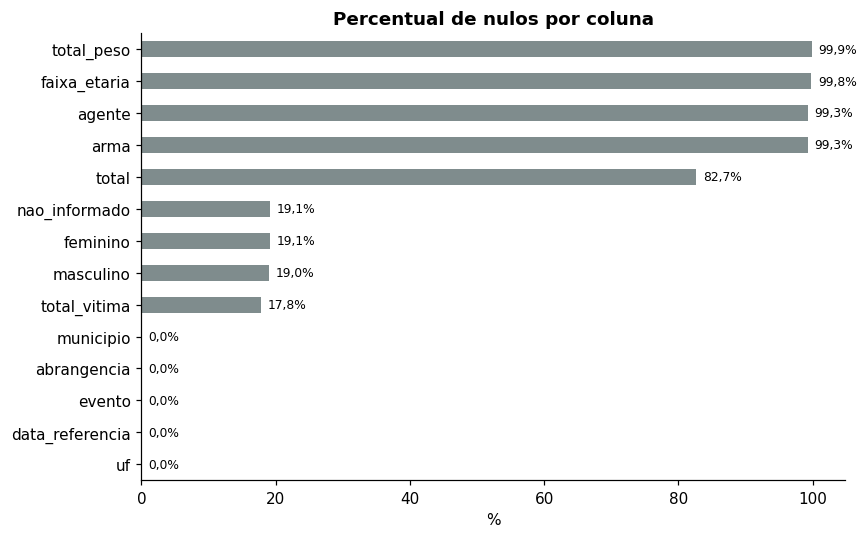

In [5]:
nulos = pd.DataFrame({"nulos": df_raw.isna().sum(), "% nulos": (df_raw.isna().mean() * 100).round(1)})
nulos = nulos.sort_values("% nulos", ascending=False)
display(nulos)

ax = nulos["% nulos"].sort_values().plot.barh(figsize=(8, 5), color="#7f8c8d")
ax.set_title("Percentual de nulos por coluna", fontweight="bold"); ax.set_xlabel("%")
for i, v in enumerate(nulos["% nulos"].sort_values()):
    ax.text(v + 1, i, f"{v:.1f}%".replace(".", ","), va="center", fontsize=8)
plt.tight_layout(); plt.show()

### 4.2 Nulos estruturais × nulos reais
Muitos nulos **não são erro**: a coluna simplesmente não se aplica ao tipo de evento (ex.: `arma` só existe em "Arma de Fogo Apreendida"). A tabela mostra, para cada evento, o **% de linhas preenchidas** em cada coluna.

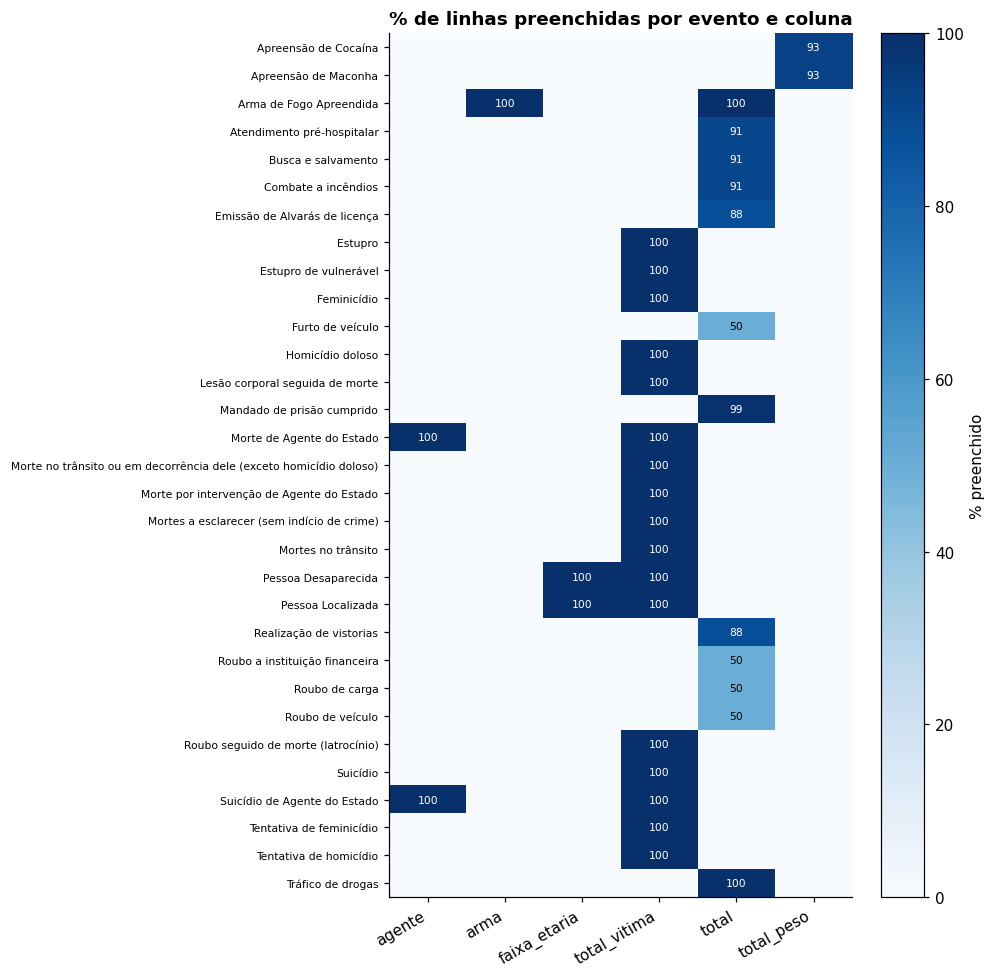

In [6]:
cols_var = ["agente", "arma", "faixa_etaria", "total_vitima", "total", "total_peso"]
preench = df_raw.groupby("evento")[cols_var].agg(lambda s: s.notna().mean() * 100).round(0)

fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(preench.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(cols_var))); ax.set_xticklabels(cols_var, rotation=30, ha="right")
ax.set_yticks(range(len(preench))); ax.set_yticklabels(preench.index, fontsize=7)
for i in range(preench.shape[0]):
    for j in range(preench.shape[1]):
        v = preench.values[i, j]
        if v > 0:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "black")
ax.set_title("% de linhas preenchidas por evento e coluna", fontweight="bold")
plt.colorbar(im, label="% preenchido"); plt.tight_layout(); plt.show()

**Leitura:** cada evento usa **uma "família" de medida**: ou `total_vitima` (contagem de vítimas), ou `total` (contagem de ocorrências), ou `total_peso` (drogas). Os nulos nessas colunas são, em grande parte, **estruturais**. O problema real são as linhas em que **nenhuma** medida foi preenchida:

In [7]:
sem_medida = df_raw[["total_vitima", "total", "total_peso"]].isna().all(axis=1)
print(f"Linhas sem nenhuma medida: {br(sem_medida.sum())} ({sem_medida.mean()*100:.2f}% do total)")
print("\nPor tipo de evento (top 10):")
display(df_raw[sem_medida]["evento"].value_counts().head(10).to_frame("linhas"))
print("Por origem do dado:")
display(df_raw[sem_medida]["abrangencia"].value_counts().to_frame("linhas"))

Linhas sem nenhuma medida: 2.427 (0.39% do total)

Por tipo de evento (top 10):


,linhas
evento,
Mandado de prisão cumprido,1255
Roubo de carga,244
Roubo a instituição financeira,243
Roubo de veículo,243
Furto de veículo,243
Apreensão de Cocaína,34
Apreensão de Maconha,34
Realização de vistorias,30
Emissão de Alvarás de licença,29


Por origem do dado:


,linhas
abrangencia,
Estadual,1349
Polícia Federal,1078


### 4.3 Linhas duplicadas

In [8]:
dup_flag = df_raw.duplicated(keep="first")
print(f"Linhas 100% idênticas (cópias extras): {br(dup_flag.sum())}")
print("\nPor UF:"); display(df_raw[dup_flag]["uf"].value_counts().to_frame("linhas"))
com_valor = (df_raw[dup_flag][["total_vitima", "total"]].fillna(0).sum(axis=1) > 0).sum()
print(f"Dessas, com valor maior que zero: {br(com_valor)}")
print("\nEventos mais afetados:"); display(df_raw[dup_flag]["evento"].value_counts().head(5).to_frame("linhas"))
print("Exemplo (grupo duplicado em Brasília):")
exemplo = df_raw[df_raw.duplicated(keep=False) & (df_raw["total_vitima"] > 0)].sort_values(["municipio", "evento", "data_referencia"]).head(6)
display(exemplo[["uf", "municipio", "evento", "data_referencia", "total_vitima", "abrangencia"]])

Linhas 100% idênticas (cópias extras): 3.001

Por UF:


,linhas
uf,
DF,3001


Dessas, com valor maior que zero: 434

Eventos mais afetados:


,linhas
evento,
Mandado de prisão cumprido,396
Mortes a esclarecer (sem indício de crime),288
Lesão corporal seguida de morte,286
Roubo seguido de morte (latrocínio),286
Feminicídio,278


Exemplo (grupo duplicado em Brasília):


,uf,municipio,evento,data_referencia,total_vitima,abrangencia
90109,DF,BRASÍLIA,Feminicídio,2026-01-01,1.0,Estadual
90117,DF,BRASÍLIA,Feminicídio,2026-01-01,1.0,Estadual
90159,DF,BRASÍLIA,Feminicídio,2026-02-01,1.0,Estadual
90161,DF,BRASÍLIA,Feminicídio,2026-02-01,1.0,Estadual
90229,DF,BRASÍLIA,Feminicídio,2026-05-01,1.0,Estadual
90261,DF,BRASÍLIA,Feminicídio,2026-05-01,1.0,Estadual


**Interpretação:** todas as cópias estão no **DF**. A base não tem coluna de *região administrativa*, então registros diferentes de Brasília ficam **idênticos e indistinguíveis**. Não dá para afirmar se são duplicatas reais ou regiões diferentes com o mesmo valor. Essa dúvida será tratada na análise de sensibilidade (seção 7).

### 4.4 Município: valor "NÃO INFORMADO" e nomes repetidos em UFs diferentes

In [9]:
NI = "NÃO INFORMADO"
ni = df_raw[df_raw["municipio"] == NI]
print(f"Linhas com município = '{NI}': {br(len(ni))} ({len(ni)/len(df_raw)*100:.2f}% do total), presentes em {ni['uf'].nunique()} UFs")
print(f"Nas mortes violentas, essas linhas somam apenas {int(ni[ni['evento'].isin(['Homicídio doloso','Feminicídio','Lesão corporal seguida de morte','Roubo seguido de morte (latrocínio)'])]['total_vitima'].sum())} vítimas.")
print("Eventos com mais registros 'NÃO INFORMADO':")
display(ni["evento"].value_counts().head(5).to_frame("linhas"))

mun_ufs = df_raw[df_raw["municipio"] != NI].groupby("municipio")["uf"].nunique()
homonimos = mun_ufs[mun_ufs > 1].sort_values(ascending=False)
print(f"\nNomes de município reais que existem em mais de uma UF: {len(homonimos)}")
display(homonimos.head(5).to_frame("nº de UFs"))

Linhas com município = 'NÃO INFORMADO': 18.792 (3.04% do total), presentes em 27 UFs
Nas mortes violentas, essas linhas somam apenas 5 vítimas.
Eventos com mais registros 'NÃO INFORMADO':


,linhas
evento,
Arma de Fogo Apreendida,4374
Morte de Agente do Estado,2079
Suicídio de Agente do Estado,2079
Pessoa Localizada,729
Pessoa Desaparecida,729



Nomes de município reais que existem em mais de uma UF: 232


,nº de UFs
municipio,
BOM JESUS,5
SÃO DOMINGOS,5
SANTA LUZIA,4
BONITO,4
VERA CRUZ,4


**Interpretação:**
- `NÃO INFORMADO` é um **dado faltante disfarçado**: não aparece como nulo, mas é um texto que representa "não sabemos o município". Ele existe em todas as UFs e **não é uma cidade**, então não deve entrar em análises por município.
- Agrupar só por `municipio` mistura cidades diferentes (ex.: Bom Jesus e São Domingos existem em vários estados). A chave correta é **(município, UF)**.

### 4.5 Padronização de texto e consistência dos números

In [10]:
print("Municípios com espaços sobrando:", int((df_raw["municipio"] != df_raw["municipio"].str.strip()).sum()))
print("Municípios todos em MAIÚSCULAS:", int(df_raw["municipio"].str.isupper().sum()), "de", br(len(df_raw)))
print("Datas que não são dia 1:", int((df_raw["data_referencia"].dt.day != 1).sum()))
print("Nº de eventos distintos:", df_raw["evento"].nunique(), "| origens:", df_raw["abrangencia"].unique().tolist())

num = ["feminino", "masculino", "nao_informado", "total_vitima", "total", "total_peso"]
print("\nValores negativos:", {c: int((df_raw[c] < 0).sum()) for c in num})
print("Valores não inteiros:", {c: int(((df_raw[c].dropna() % 1) != 0).sum()) for c in num})
soma_sexo = df_raw[["feminino", "masculino", "nao_informado"]].sum(axis=1, min_count=1)
incons = ((soma_sexo.notna()) & (df_raw["total_vitima"].notna()) & (soma_sexo != df_raw["total_vitima"])).sum()
print("\nLinhas em que feminino + masculino + não informado ≠ total_vitima:", int(incons))
print("Linhas com total_vitima preenchido e sexo todo nulo:", int((df_raw["total_vitima"].notna() & soma_sexo.isna()).sum()))
print("   → soma de total_vitima nessas linhas:", float(df_raw.loc[df_raw["total_vitima"].notna() & soma_sexo.isna(), "total_vitima"].sum()))

Municípios com espaços sobrando: 0
Municípios todos em MAIÚSCULAS: 618206 de 618.206
Datas que não são dia 1: 0
Nº de eventos distintos: 31 | origens: ['Estadual', 'Polícia Federal', 'Polícia Rodoviária Federal']

Valores negativos: {'feminino': 0, 'masculino': 0, 'nao_informado': 0, 'total_vitima': 0, 'total': 0, 'total_peso': 0}
Valores não inteiros: {'feminino': 0, 'masculino': 0, 'nao_informado': 0, 'total_vitima': 0, 'total': 0, 'total_peso': 749}

Linhas em que feminino + masculino + não informado ≠ total_vitima: 0
Linhas com total_vitima preenchido e sexo todo nulo: 7221
   → soma de total_vitima nessas linhas: 0.0


**Interpretação:** os números são internamente consistentes (sem negativos, e a soma por sexo bate). Os "não inteiros" são de `total_peso` (quilos de droga), que é esperado. As linhas com sexo todo nulo têm `total_vitima = 0`, ou seja, são **zeros não preenchidos**, e não perda de informação.

### 4.6 Anomalias na série temporal (mudanças bruscas)
Procuramos meses em que o total de homicídios dolosos de uma UF **mais que dobra ou cai mais de 60%** em relação ao mês anterior.

,UF,Mês,Mês anterior,Mês do salto,Razão
0,DF,Fev/26,18,5,0.28
1,DF,Mar/26,5,22,4.40
2,MS,Mar/26,11,42,3.82


UFs com anomalia: ['DF', 'MS']


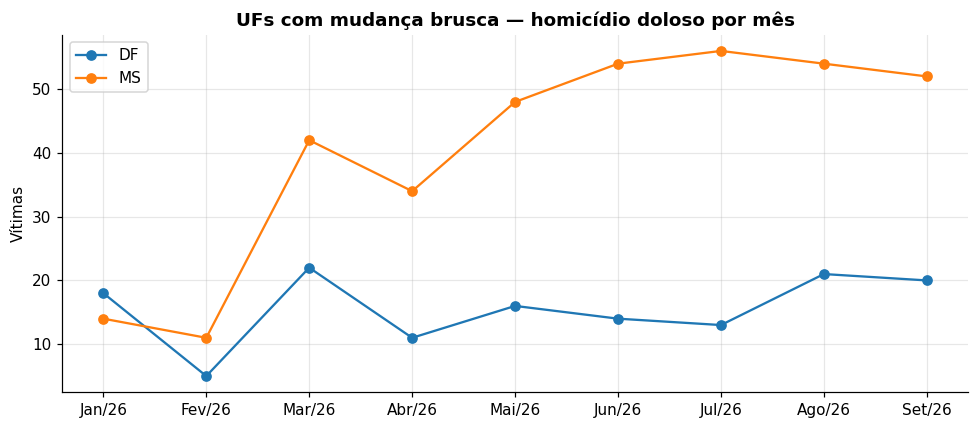

In [11]:
hd_raw = df_raw[df_raw["evento"] == "Homicídio doloso"]
serie_uf = hd_raw.groupby(["uf", "data_referencia"])["total_vitima"].sum().unstack(fill_value=0)
meses = list(serie_uf.columns)
ant, atu = serie_uf.iloc[:, :-1].values, serie_uf.iloc[:, 1:].values
with np.errstate(divide="ignore", invalid="ignore"):
    razao = np.where(ant > 0, atu / ant, np.nan)
achados = [{"UF": serie_uf.index[i], "Mês": rotulo_mes(meses[j + 1]), "Mês anterior": int(ant[i, j]),
            "Mês do salto": int(atu[i, j]), "Razão": round(float(razao[i, j]), 2)}
           for i, j in np.argwhere((razao > 2) | (razao < 0.4))]
anom = pd.DataFrame(achados)
UFS_ANOMALAS = sorted(set(anom["UF"])) if len(anom) else []
display(anom)
print("UFs com anomalia:", UFS_ANOMALAS)

if UFS_ANOMALAS:
    fig, ax = plt.subplots(figsize=(9, 4))
    for uf in UFS_ANOMALAS:
        ax.plot(range(len(meses)), serie_uf.loc[uf].values, marker="o", label=uf)
    eixo_meses(ax, meses); ax.legend()
    ax.set_title("UFs com mudança brusca — homicídio doloso por mês", fontweight="bold"); ax.set_ylabel("Vítimas")
    plt.tight_layout(); plt.show()

**Interpretação:** saltos grandes e abruptos como esses sugerem **mudança na forma de registrar ou enviar os dados** (ou atraso de envio), e não variação real da violência. Não temos como confirmar a causa, então essas UFs serão **sinalizadas** e testadas na análise de sensibilidade, e não apagadas.

### 4.7 Valores extremos (outliers) por município
Considerando só os registros com ao menos 1 homicídio (a maioria dos registros é zero), usamos o critério de Tukey (acima de Q3 + 3·IQR).

In [12]:
pos = hd_raw[(hd_raw["total_vitima"] > 0) & (hd_raw["municipio"] != NI)]
q1, q3 = pos["total_vitima"].quantile([.25, .75]); iqr = q3 - q1; limite = q3 + 3 * iqr
out = pos[pos["total_vitima"] > limite]
print(f"Limite superior: {limite:.0f} vítimas/mês | outliers: {br(len(out))} de {br(len(pos))} registros positivos")
print("Municípios com mais registros extremos:")
display(out.groupby(["municipio", "uf"]).size().sort_values(ascending=False).head(8).to_frame("meses extremos"))

Limite superior: 5 vítimas/mês | outliers: 542 de 9.098 registros positivos
Municípios com mais registros extremos:


,,meses extremos
municipio,uf,
BELFORD ROXO,RJ,9
BELO HORIZONTE,MG,9
PETROLINA,PE,9
MOSSORÓ,RN,9
NATAL,RN,9
NOVA IGUAÇU,RJ,9
SALVADOR,BA,9
MANAUS,AM,9


**Interpretação:** os extremos são **cidades grandes e médias** que registram homicídios em todos os meses (capitais e municípios da região metropolitana, por exemplo). São valores **reais**, e não erros, por isso serão mantidos. Ser outlier estatístico não significa estar errado.

### 4.8 Resumo do diagnóstico

In [13]:
resumo = pd.DataFrame([
    ["Nulos estruturais (colunas que só valem para certos eventos)", "agente, arma, faixa_etaria, total, total_peso, total_vitima", "Faltante (esperado)", "Manter e tratar por tipo de evento"],
    ["Linhas sem nenhuma medida", br(sem_medida.sum()), "Faltante (real)", "Remover"],
    ["Linhas 100% idênticas (DF)", br(dup_flag.sum()), "Repetido / ambíguo", "Sinalizar e testar na sensibilidade"],
    ["Município = 'NÃO INFORMADO' (nulo disfarçado)", br(len(ni)), "Faltante (disfarçado)", "Manter, sinalizar e excluir das análises por município"],
    ["Nomes de município em mais de uma UF", br(len(homonimos)), "Ambíguo", "Usar chave (município, UF)"],
    ["Mudança brusca na série (UFs)", ", ".join(UFS_ANOMALAS) if UFS_ANOMALAS else "nenhuma", "Possível erro de registro", "Sinalizar e testar na sensibilidade"],
    ["Texto todo em maiúsculas", br(len(df_raw)), "Padronização", "Converter para título"],
    ["Zeros não preenchidos nas colunas de sexo", "ver 4.5", "Faltante (zero)", "Preencher com 0"],
    ["Medidas em colunas diferentes (vítimas × ocorrências × peso)", "3 colunas", "Estrutura", "Criar coluna única `valor` + tipo da medida"],
], columns=["Problema", "Quantidade / onde", "Tipo", "Decisão"])
resumo

,Problema,Quantidade / onde,Tipo,Decisão
0,Nulos estruturais (colunas que só valem para c...,"agente, arma, faixa_etaria, total, total_peso,...",Faltante (esperado),Manter e tratar por tipo de evento
1,Linhas sem nenhuma medida,2.427,Faltante (real),Remover
2,Linhas 100% idênticas (DF),3.001,Repetido / ambíguo,Sinalizar e testar na sensibilidade
3,Município = 'NÃO INFORMADO' (nulo disfarçado),18.792,Faltante (disfarçado),"Manter, sinalizar e excluir das análises por m..."
4,Nomes de município em mais de uma UF,232,Ambíguo,"Usar chave (município, UF)"
5,Mudança brusca na série (UFs),"DF, MS",Possível erro de registro,Sinalizar e testar na sensibilidade
6,Texto todo em maiúsculas,618.206,Padronização,Converter para título
7,Zeros não preenchidos nas colunas de sexo,ver 4.5,Faltante (zero),Preencher com 0
8,Medidas em colunas diferentes (vítimas × ocorr...,3 colunas,Estrutura,Criar coluna única `valor` + tipo da medida


## 5. Limpeza e tratamento
Cada passo registra o que foi feito e quantas linhas foram afetadas.

In [14]:
df = df_raw.copy()
registro = []   # (passo, descrição, linhas afetadas)

# L1. Sinalizar cópias idênticas ANTES de qualquer outra alteração
df["possivel_duplicata"] = df_raw.duplicated(keep="first")
registro.append(("L1", "Sinalizar linhas 100% idênticas (não removidas)", int(df["possivel_duplicata"].sum())))

# L2. Remover linhas sem nenhuma medida
n = int(sem_medida.sum())
df = df[~sem_medida].copy()
registro.append(("L2", "Remover linhas sem nenhuma medida", n))

# L3. Texto: título + preposições em minúscula + chave (município, UF)
df["municipio"] = df["municipio"].str.strip().str.title()
for prep in [" De ", " Da ", " Do ", " Das ", " Dos ", " E "]:
    df["municipio"] = df["municipio"].str.replace(prep, prep.lower(), regex=False)
df["mun_uf"] = df["municipio"] + " - " + df["uf"]
df["mun_desconhecido"] = df["municipio"].str.upper() == NI.upper()
registro.append(("L3", "Padronizar nomes, criar chave (município, UF) e sinalizar 'NÃO INFORMADO'", int(len(df))))

# L4. Colunas de sexo: nulo vira 0 quando total_vitima existe (soma já bate com o total)
cols_sexo = ["feminino", "masculino", "nao_informado"]
mask = df["total_vitima"].notna()
n4 = int(df.loc[mask, cols_sexo].isna().sum().sum())
df.loc[mask, cols_sexo] = df.loc[mask, cols_sexo].fillna(0)
registro.append(("L4", "Preencher com 0 os nulos de sexo onde há total_vitima", n4))

# L5. Medida única: vítimas quando existe, senão ocorrências
df["valor"] = df["total_vitima"].fillna(df["total"])
df["tipo_medida"] = np.where(df["total_vitima"].notna(), "vítimas", np.where(df["total"].notna(), "ocorrências", "peso (kg)"))
registro.append(("L5", "Criar coluna única `valor` e `tipo_medida`", int(len(df))))

# L6. Tipos de dados corretos (inteiros, categorias) e colunas de tempo/região
for c in cols_sexo + ["total_vitima", "total", "valor"]:
    df[c] = df[c].astype("Int64")
for c in ["uf", "evento", "abrangencia", "tipo_medida", "agente", "arma", "faixa_etaria"]:
    df[c] = df[c].astype("category")
df["ano"] = df["data_referencia"].dt.year
df["mes"] = df["data_referencia"].dt.month
REGIAO = {"Norte": ["AC","AP","AM","PA","RO","RR","TO"], "Nordeste": ["AL","BA","CE","MA","PB","PE","PI","RN","SE"],
          "Centro-Oeste": ["DF","GO","MT","MS"], "Sudeste": ["ES","MG","RJ","SP"], "Sul": ["PR","RS","SC"]}
uf2reg = {uf: r for r, ufs in REGIAO.items() for uf in ufs}
df["regiao"] = df["uf"].astype(str).map(uf2reg)
registro.append(("L6", "Ajustar tipos (Int64, category), criar ano, mês e região", int(len(df))))

# L7. Sinalizar UFs com anomalia (sem apagar)
df["uf_anomala"] = df["uf"].astype(str).isin(UFS_ANOMALAS)
registro.append(("L7", f"Sinalizar UFs com mudança brusca ({', '.join(UFS_ANOMALAS) or 'nenhuma'})", int(df["uf_anomala"].sum())))

pd.DataFrame(registro, columns=["Passo", "O que foi feito", "Linhas/valores afetados"])

,Passo,O que foi feito,Linhas/valores afetados
0,L1,Sinalizar linhas 100% idênticas (não removidas),3001
1,L2,Remover linhas sem nenhuma medida,2427
2,L3,"Padronizar nomes, criar chave (município, UF) ...",615779
3,L4,Preencher com 0 os nulos de sexo onde há total...,22958
4,L5,Criar coluna única `valor` e `tipo_medida`,615779
5,L6,"Ajustar tipos (Int64, category), criar ano, mê...",615779
6,L7,"Sinalizar UFs com mudança brusca (DF, MS)",13262


### 5.1 Antes × depois

In [15]:
def perfil(d):
    return {"Linhas": len(d), "Colunas": d.shape[1], "Células nulas": int(d.isna().sum().sum()),
            "Linhas sem medida": int(d[["total_vitima", "total", "total_peso"]].isna().all(axis=1).sum()),
            "Memória (MB)": round(d.memory_usage(deep=True).sum() / 1e6, 1)}
comp = pd.DataFrame({"Bruto": perfil(df_raw), "Tratado": perfil(df)})
display(comp)

df.to_parquet("BancoVDE_2026_tratado.parquet", index=False)
print("Base tratada salva em BancoVDE_2026_tratado.parquet")
# No Colab, para baixar o arquivo tratado, descomente:
# from google.colab import files; files.download("BancoVDE_2026_tratado.parquet")
df.head()

,Bruto,Tratado
Linhas,618206.0,615779.0
Colunas,14.0,23.0
Células nulas,3437364.0,3393472.0
Linhas sem medida,2427.0,0.0
Memória (MB),272.1,180.0


Base tratada salva em BancoVDE_2026_tratado.parquet


,uf,municipio,evento,data_referencia,agente,arma,faixa_etaria,feminino,masculino,nao_informado,total_vitima,total,total_peso,abrangencia,possivel_duplicata,mun_uf,mun_desconhecido,valor,tipo_medida,ano,mes,regiao,uf_anomala
0,AC,Acrelândia,Feminicídio,2026-01-01,NaN,NaN,NaN,0,0,0,0,<NA>,NaN,Estadual,False,Acrelândia - AC,False,0,vítimas,2026,1,Norte,False
1,AC,Acrelândia,Feminicídio,2026-02-01,NaN,NaN,NaN,0,0,0,0,<NA>,NaN,Estadual,False,Acrelândia - AC,False,0,vítimas,2026,2,Norte,False
2,AC,Acrelândia,Feminicídio,2026-03-01,NaN,NaN,NaN,0,0,0,0,<NA>,NaN,Estadual,False,Acrelândia - AC,False,0,vítimas,2026,3,Norte,False
3,AC,Acrelândia,Feminicídio,2026-04-01,NaN,NaN,NaN,0,0,0,0,<NA>,NaN,Estadual,False,Acrelândia - AC,False,0,vítimas,2026,4,Norte,False
4,AC,Acrelândia,Feminicídio,2026-05-01,NaN,NaN,NaN,0,0,0,0,<NA>,NaN,Estadual,False,Acrelândia - AC,False,0,vítimas,2026,5,Norte,False


**Observação:** a quantidade de células nulas quase não cai porque a maior parte dos nulos é **estrutural** (a coluna não se aplica ao evento) e foi **mantida de propósito**. Preencher esses nulos inventaria informação.

## 6. Análises
Foco: **mortes violentas intencionais** (homicídio doloso, feminicídio, latrocínio e lesão corporal seguida de morte).

### 6.1 Estatística descritiva do homicídio doloso por município e mês (municípios conhecidos)

,valor
Observações (município × mês),50418.00
Média,0.41
Mediana,0.00
Desvio-padrão,2.13
Coef. de variação,5.19
Mínimo,0.00
Percentil 90,1.00
Percentil 99,6.00
Máximo,120.00
% de zeros,81.95


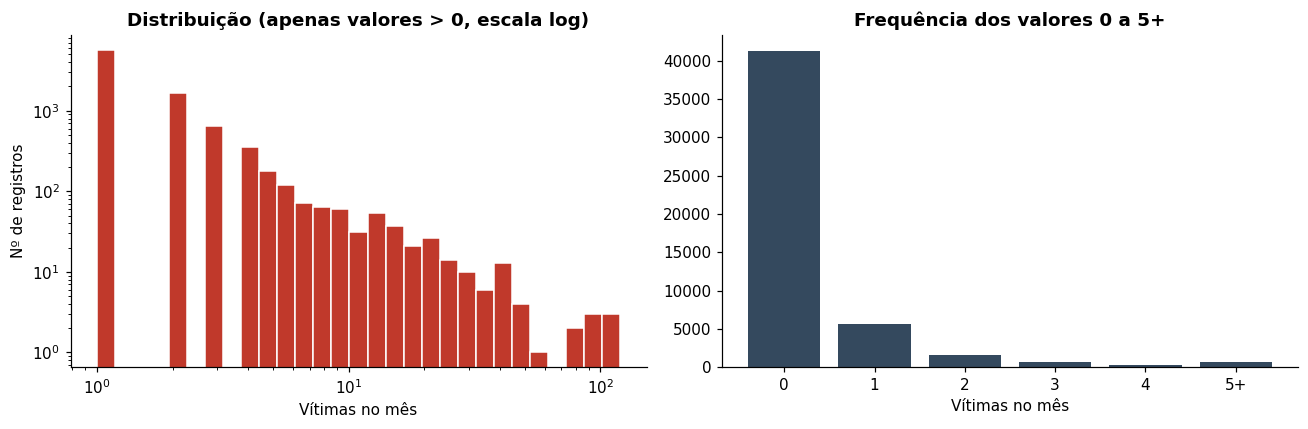

In [16]:
CONS = ["Homicídio doloso", "Feminicídio", "Lesão corporal seguida de morte", "Roubo seguido de morte (latrocínio)"]
cons = df[df["evento"].isin(CONS)].copy()
cons["evento"] = cons["evento"].astype(str)
cons["total_vitima"] = cons["total_vitima"].astype(int)
hd = cons[cons["evento"] == "Homicídio doloso"]

hd_mun = hd[~hd["mun_desconhecido"]]
x = hd_mun["total_vitima"]
desc = pd.DataFrame({"valor": {
    "Observações (município × mês)": len(x), "Média": x.mean(), "Mediana": x.median(), "Desvio-padrão": x.std(),
    "Coef. de variação": x.std() / x.mean(), "Mínimo": x.min(), "Percentil 90": x.quantile(.9),
    "Percentil 99": x.quantile(.99), "Máximo": x.max(), "% de zeros": (x == 0).mean() * 100,
    "Assimetria (skewness)": stats.skew(x), "Curtose": stats.kurtosis(x)}})
display(desc.round(2))

pos = x[x > 0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pos, bins=np.logspace(0, np.log10(pos.max()), 30), color="#c0392b", edgecolor="white")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("Distribuição (apenas valores > 0, escala log)", fontweight="bold"); ax[0].set_xlabel("Vítimas no mês"); ax[0].set_ylabel("Nº de registros")
vc = x.clip(upper=5).value_counts().sort_index()
ax[1].bar([str(i) if i < 5 else "5+" for i in vc.index], vc.values, color="#34495e")
ax[1].set_title("Frequência dos valores 0 a 5+", fontweight="bold"); ax[1].set_xlabel("Vítimas no mês")
plt.tight_layout(); plt.show()

**Interpretação:** a distribuição é **extremamente assimétrica à direita**, com a maioria de zeros e poucos valores muito altos (capitais). A média é muito maior que a mediana e o desvio-padrão supera a média. Por isso médias simples enganam e usamos **testes não paramétricos** (Spearman, Kruskal-Wallis, Theil-Sen).

### 6.2 Agregando por UF e mês
Como o nível município × mês é muito esparso, somamos por **UF × mês** (27 UFs × 9 meses).

,Total,Média mensal,Mediana,Desvio-padrão,Coef. de variação
uf,,,,,
RJ,2378,264.22,263.0,29.31,0.11
BA,2246,249.56,242.0,27.83,0.11
PE,1923,213.67,208.0,18.73,0.09
SP,1558,173.11,174.0,19.86,0.11
MG,1460,162.22,161.0,10.54,0.07
MA,1285,142.78,148.0,19.34,0.14
PA,1212,134.67,135.0,17.71,0.13
CE,1144,127.11,120.0,23.67,0.19
PR,800,88.89,84.0,16.67,0.19


Teste de normalidade (Shapiro-Wilk) em 243 observações UF×mês:
   dados originais: W = 0.869, p = 1.35e-13
   após log(1+x):   W = 0.972, p = 1.07e-04


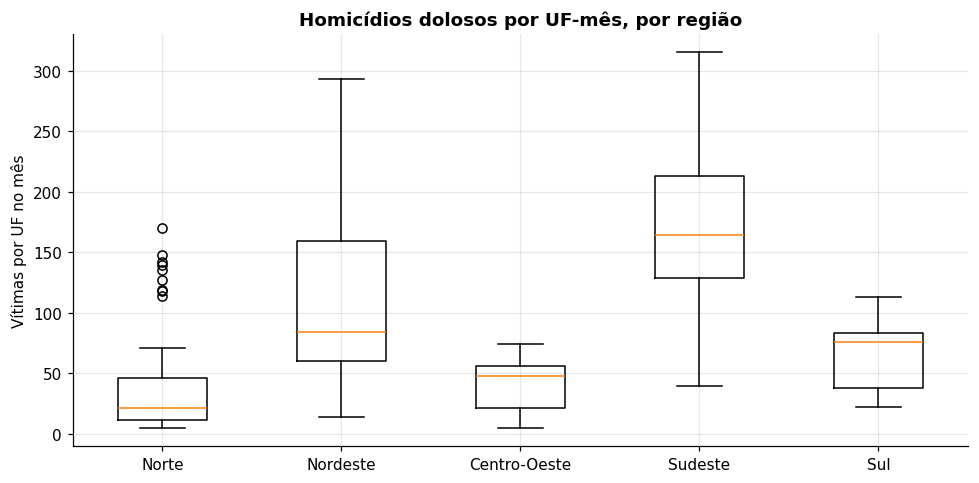

In [17]:
uf_mes = hd.groupby(["uf", "data_referencia"], observed=True)["total_vitima"].sum().unstack(fill_value=0)
meses = list(uf_mes.columns)
tab_uf = pd.DataFrame({"Total": uf_mes.sum(axis=1), "Média mensal": uf_mes.mean(axis=1), "Mediana": uf_mes.median(axis=1),
                       "Desvio-padrão": uf_mes.std(axis=1)})
tab_uf["Coef. de variação"] = tab_uf["Desvio-padrão"] / tab_uf["Média mensal"]
tab_uf = tab_uf.sort_values("Total", ascending=False)
display(tab_uf.round(2).head(10))

vals = uf_mes.values.flatten()
w, p = stats.shapiro(vals); w2, p2 = stats.shapiro(np.log1p(vals))
print(f"Teste de normalidade (Shapiro-Wilk) em {len(vals)} observações UF×mês:")
print(f"   dados originais: W = {w:.3f}, p = {p:.2e}")
print(f"   após log(1+x):   W = {w2:.3f}, p = {p2:.2e}")

reg_vals = {r: uf_mes.loc[[u for u in ufs if u in uf_mes.index]].values.flatten() for r, ufs in REGIAO.items()}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(list(reg_vals.values()), showfliers=True)
ax.set_xticklabels(list(reg_vals.keys()))
ax.set_title("Homicídios dolosos por UF-mês, por região", fontweight="bold"); ax.set_ylabel("Vítimas por UF no mês"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretação:** mesmo agregando, os dados **não são normais** (p muito pequeno). Isso confirma a escolha de testes não paramétricos. O coeficiente de variação alto em alguns estados indica meses muito diferentes entre si.

### 6.3 Série nacional mensal e tendência

evento,Homicídio doloso,Feminicídio,Total de mortes violentas,Variação % mês a mês,Média móvel 3m
Jan/26,2594,144,2849,NaN,NaN
Fev/26,2291,127,2536,-11.0,NaN
Mar/26,2451,137,2690,6.1,2691.7
Abr/26,2215,111,2415,-10.2,2547.0
Mai/26,2223,116,2428,0.5,2511.0
Jun/26,2189,109,2392,-1.5,2411.7
Jul/26,2190,105,2371,-0.9,2397.0
Ago/26,2302,132,2524,6.5,2429.0
Set/26,2268,101,2457,-2.7,2450.7


,Inclinação (reg. linear),p (reg. linear),R²,Tau de Kendall,p (Mann-Kendall),Inclinação Theil-Sen,IC 95% Theil-Sen,Variação % (1º vs último trimestre)
Total de mortes violentas,-37.75,0.055628,0.428762,-0.444444,0.119439,-34.6,[-79.7 ; 8.4],-8.95356
Homicídio doloso,-30.316667,0.080658,0.372955,-0.333333,0.259518,-24.083333,[-67.3 ; 10.6],-7.85169
Feminicídio,-3.716667,0.049592,0.445228,-0.611111,0.024741,-3.875,[-7.0 ; -1.0],-17.156863


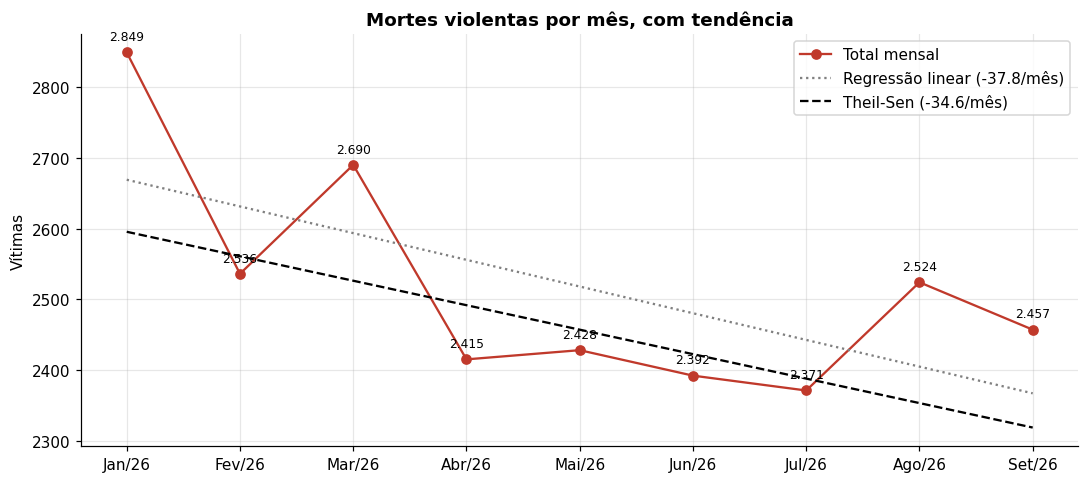

In [18]:
nac = cons.groupby(["data_referencia", "evento"])["total_vitima"].sum().unstack(fill_value=0)
nac["Total de mortes violentas"] = nac[CONS].sum(axis=1)
tab_nac = nac[["Homicídio doloso", "Feminicídio", "Total de mortes violentas"]].copy()
tab_nac["Variação % mês a mês"] = (tab_nac["Total de mortes violentas"].pct_change() * 100).round(1)
tab_nac["Média móvel 3m"] = tab_nac["Total de mortes violentas"].rolling(3).mean().round(1)
tab_nac.index = [rotulo_mes(t) for t in tab_nac.index]
display(tab_nac)

def tendencia(serie):
    y = np.asarray(serie, dtype=float); t = np.arange(len(y))
    lr = stats.linregress(t, y)
    tau, p_mk = stats.kendalltau(t, y)
    sen = stats.theilslopes(y, t)
    n = min(3, len(y) // 2)
    var = (y[-n:].mean() - y[:n].mean()) / y[:n].mean() * 100
    return {"Inclinação (reg. linear)": lr.slope, "p (reg. linear)": lr.pvalue, "R²": lr.rvalue ** 2,
            "Tau de Kendall": tau, "p (Mann-Kendall)": p_mk, "Inclinação Theil-Sen": sen[0],
            "IC 95% Theil-Sen": f"[{sen[2]:.1f} ; {sen[3]:.1f}]", "Variação % (1º vs último trimestre)": var}
resultados = pd.DataFrame({c: tendencia(nac[c]) for c in ["Total de mortes violentas", "Homicídio doloso", "Feminicídio"]}).T
display(resultados.round(3))

y = nac["Total de mortes violentas"].values; t = np.arange(len(y))
lr = stats.linregress(t, y); sen = stats.theilslopes(y, t)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t, y, marker="o", color="#c0392b", label="Total mensal")
ax.plot(t, lr.intercept + lr.slope * t, ls=":", color="gray", label=f"Regressão linear ({lr.slope:+.1f}/mês)")
ax.plot(t, sen[1] + sen[0] * t, ls="--", color="black", label=f"Theil-Sen ({sen[0]:+.1f}/mês)")
eixo_meses(ax, nac.index); ax.legend(); ax.set_ylabel("Vítimas")
ax.set_title("Mortes violentas por mês, com tendência", fontweight="bold")
for ti, yi in zip(t, y): ax.annotate(br(yi), (ti, yi), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.tight_layout(); plt.show()

**Interpretação:** a inclinação negativa indica **queda ao longo dos meses**. Com apenas **9 pontos**, o poder dos testes é baixo: veja os valores de p antes de falar em significância. Se p > 0,05, dizemos que há *indício* de queda, mas **não evidência estatística forte**.

### 6.4 Correlação entre tipos de morte (Spearman, UF × mês)

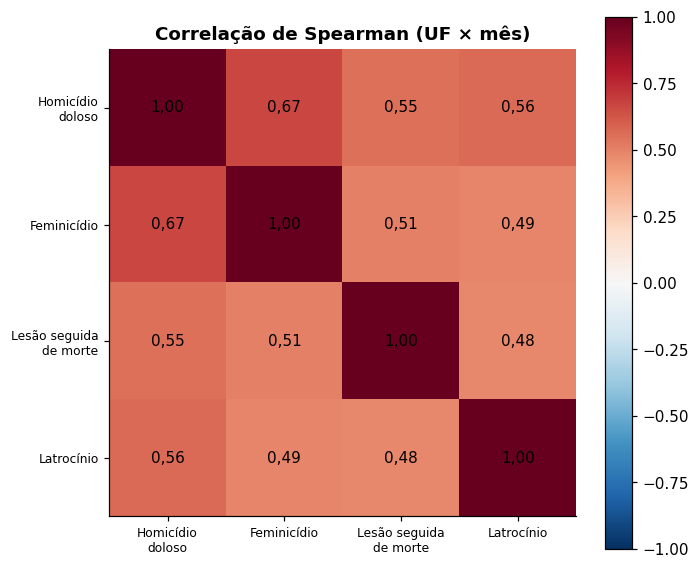

Homicídio doloso × Feminicídio: rho = 0.67, p = 1.25e-32  (n = 243)


In [19]:
piv = cons.groupby(["uf", "data_referencia", "evento"], observed=True)["total_vitima"].sum().unstack(fill_value=0)[CONS]
corr = piv.corr(method="spearman")
curtos = ["Homicídio\ndoloso", "Feminicídio", "Lesão seguida\nde morte", "Latrocínio"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(curtos, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(curtos, fontsize=8)
for i in range(4):
    for j in range(4): ax.text(j, i, f"{corr.values[i, j]:.2f}".replace(".", ","), ha="center", va="center")
ax.set_title("Correlação de Spearman (UF × mês)", fontweight="bold"); plt.colorbar(im); plt.tight_layout(); plt.show()
rho, p = stats.spearmanr(piv["Homicídio doloso"], piv["Feminicídio"])
print(f"Homicídio doloso × Feminicídio: rho = {rho:.2f}, p = {p:.2e}  (n = {len(piv)})")

**Interpretação:** estados com mais homicídios também têm mais feminicídios, mas isso reflete em grande parte o **tamanho da população** (estados maiores têm mais de tudo). Correlação **não** implica causa. O ideal seria usar taxa por 100 mil habitantes.

### 6.5 Comparação entre regiões (Kruskal-Wallis)
H0: a distribuição mensal de homicídios por UF é a mesma nas 5 regiões.

In [20]:
H, p = stats.kruskal(*[v for v in reg_vals.values()])
n_total = sum(len(v) for v in reg_vals.values()); k = len(reg_vals)
eps2 = (H - k + 1) / (n_total - k)
print(f"Kruskal-Wallis: H = {H:.2f}, p = {p:.2e}, tamanho de efeito (epsilon²) = {eps2:.3f}")
print("Mediana mensal por UF, por região:")
display(pd.Series({r: np.median(v) for r, v in reg_vals.items()}, name="mediana").to_frame().round(1))

Kruskal-Wallis: H = 100.77, p = 6.75e-21, tamanho de efeito (epsilon²) = 0.407
Mediana mensal por UF, por região:


,mediana
Norte,21.0
Nordeste,84.0
Centro-Oeste,48.0
Sudeste,164.5
Sul,76.0


**Interpretação:** se p < 0,05, rejeitamos H0: há diferença entre regiões. O tamanho de efeito mostra se essa diferença é grande ou pequena na prática. Lembrar que regiões têm números diferentes de UFs e populações.

### 6.6 Perfil por sexo: intervalo de confiança e qui-quadrado

Homicídio doloso — mulheres: 6.66% (IC 95% Wilson: 6.33% a 7.01%), n = 20.723


,masculino,feminino
evento,,
Homicídio doloso,19029,1381
Feminicídio,16,1063
Lesão corporal seguida de morte,388,20
Roubo seguido de morte (latrocínio),398,48


Qui-quadrado (sexo × tipo de morte): chi² = 8662.4, gl = 3, p < 1e-300, V de Cramér = 0.623


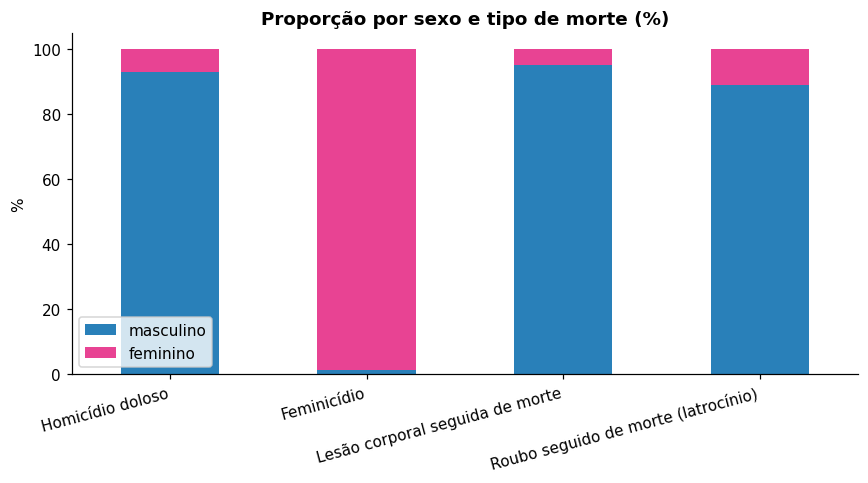

In [21]:
h = hd[["feminino", "masculino", "nao_informado"]].astype(int).sum()
n = h.sum(); pf = h["feminino"] / n; z = 1.96
centro = (pf + z**2 / (2 * n)) / (1 + z**2 / n)
meia = z * np.sqrt(pf * (1 - pf) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
print(f"Homicídio doloso — mulheres: {pf*100:.2f}% (IC 95% Wilson: {100*(centro-meia):.2f}% a {100*(centro+meia):.2f}%), n = {br(n)}")

tab = cons.groupby("evento")[["masculino", "feminino"]].apply(lambda d: d.astype(int).sum())
tab = tab.loc[CONS]
chi2, p, dof, esp = stats.chi2_contingency(tab.values)
v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
display(tab)
p_txt = "p < 1e-300" if p == 0 else f"p = {p:.2e}"
print(f"Qui-quadrado (sexo × tipo de morte): chi² = {chi2:.1f}, gl = {dof}, {p_txt}, V de Cramér = {v:.3f}")
(tab.div(tab.sum(axis=1), axis=0) * 100).round(1).plot.bar(stacked=True, figsize=(8, 4.5), color=["#2980b9", "#e84393"])
plt.title("Proporção por sexo e tipo de morte (%)", fontweight="bold"); plt.ylabel("%"); plt.xlabel(""); plt.xticks(rotation=15, ha="right")
plt.tight_layout(); plt.show()

**Interpretação:** o sexo da vítima **depende do tipo de crime** (p muito pequeno). No feminicídio, por definição, todas são mulheres, o que ajuda a puxar essa associação. Entre os outros crimes, as vítimas são majoritariamente homens.

## 7. Análise de sensibilidade
**Pergunta:** as decisões de limpeza mudam as conclusões? Refazemos o total de homicídios dolosos e a tendência em três cenários. (O cenário C também elimina as cópias, pois todas estão no DF.)

In [22]:
def resumo_cenario(d):
    s = d.groupby("data_referencia", observed=True)["total_vitima"].sum()
    y = s.values.astype(float); t = np.arange(len(y))
    sen = stats.theilslopes(y, t); tau, p = stats.kendalltau(t, y)
    n = 3; var = (y[-n:].mean() - y[:n].mean()) / y[:n].mean() * 100
    return {"Total": int(y.sum()), "Média mensal": y.mean(), "Variação % (1º vs último tri.)": var,
            "Theil-Sen (vítimas/mês)": sen[0], "p (Mann-Kendall)": p}

base = hd.copy()
cen = {"A. Base tratada (padrão)": base,
       "B. Sem as cópias idênticas do DF": base[~base["possivel_duplicata"]],
       "C. Sem as UFs com anomalia (DF e MS)": base[~base["uf_anomala"]]}
sens = pd.DataFrame({k: resumo_cenario(v) for k, v in cen.items()}).T
display(sens.round(3))

,Total,Média mensal,Variação % (1º vs último tri.),Theil-Sen (vítimas/mês),p (Mann-Kendall)
A. Base tratada (padrão),20723.0,2302.556,-7.852,-24.083,0.260
B. Sem as cópias idênticas do DF,20647.0,2294.111,-7.880,-25.292,0.173
C. Sem as UFs com anomalia (DF e MS),20218.0,2246.444,-9.413,-31.417,0.075


**Interpretação:** compare a **direção** (queda ou alta), o tamanho da variação e o p entre os cenários. Se a direção e a ordem de grandeza se mantêm, a conclusão é **robusta** às decisões de limpeza. Se o p muda de lado do 0,05, o resultado depende da decisão e isso deve ser dito.

## 8. Conclusões e limitações

In [23]:
res = resultados.loc["Total de mortes violentas"]
fem = resultados.loc["Feminicídio"]
def sig(p): return "estatisticamente significativa (p < 0,05)" if p < 0.05 else "NÃO significativa a 5%"
vb = lambda x, c=1: f"{x:+.{c}f}".replace(".", ",")
print(f"Período: {rotulo_mes(nac.index[0])} a {rotulo_mes(nac.index[-1])} ({len(nac)} meses)\n")
print("QUALIDADE DOS DADOS")
print(f" • Base bruta: {br(len(df_raw))} linhas e {df_raw.shape[1]} colunas; {br(df_raw.isna().sum().sum())} células nulas.")
print(f" • {br(sem_medida.sum())} linhas sem medida (removidas); {br(dup_flag.sum())} linhas idênticas no DF (sinalizadas); {br(len(ni))} linhas com município 'NÃO INFORMADO'; {len(homonimos)} nomes de município repetidos entre UFs.")
print(f" • UFs com mudança brusca de registro: {', '.join(UFS_ANOMALAS) or 'nenhuma'}.")
print(f" • Base tratada: {br(len(df))} linhas; foco analítico em {br(len(cons))} linhas de mortes violentas.\n")
print("RESULTADOS")
print(f" • Mortes violentas: {br(nac['Total de mortes violentas'].sum())} vítimas; média de {br(nac['Total de mortes violentas'].mean())} por mês.")
print(f" • Total: variação de {vb(res['Variação % (1º vs último trimestre)'])}% (1º vs último trimestre); tendência Theil-Sen de {vb(res['Inclinação Theil-Sen'])} vítimas/mês, p (Mann-Kendall) = {str(round(res['p (Mann-Kendall)'],3)).replace('.', ',')}"+ f" → {sig(res['p (Mann-Kendall)'])}.")
print(f" • Feminicídio: variação de {vb(fem['Variação % (1º vs último trimestre)'])}%; tendência de {vb(fem['Inclinação Theil-Sen'])} vítimas/mês, p = {str(round(fem['p (Mann-Kendall)'],3)).replace('.', ',')} → {sig(fem['p (Mann-Kendall)'])}.")
print(f" • Mulheres: {str(round(pf*100,1)).replace('.', ',')}% das vítimas de homicídio doloso.")
print(f" • Sensibilidade: variação do homicídio doloso entre {vb(sens['Variação % (1º vs último tri.)'].max())}% e {vb(sens['Variação % (1º vs último tri.)'].min())}% conforme o cenário; p entre {str(round(sens['p (Mann-Kendall)'].min(),3)).replace('.', ',')} e {str(round(sens['p (Mann-Kendall)'].max(),3)).replace('.', ',')}.\n")
print("LIMITAÇÕES")
print(" • Só 9 meses de dados: baixo poder estatístico para detectar tendência.")
print(" • Sem população, não dá para calcular taxa por 100 mil habitantes; comparações entre UFs refletem o tamanho.")
print(" • Os registros são oficiais e podem ter subnotificação e atraso, principalmente no último mês.")
print(" • As anomalias detectadas não foram confirmadas na fonte.")

Período: Jan/26 a Set/26 (9 meses)

QUALIDADE DOS DADOS
 • Base bruta: 618.206 linhas e 14 colunas; 3.437.364 células nulas.
 • 2.427 linhas sem medida (removidas); 3.001 linhas idênticas no DF (sinalizadas); 18.792 linhas com município 'NÃO INFORMADO'; 232 nomes de município repetidos entre UFs.
 • UFs com mudança brusca de registro: DF, MS.
 • Base tratada: 615.779 linhas; foco analítico em 202.644 linhas de mortes violentas.

RESULTADOS
 • Mortes violentas: 22.662 vítimas; média de 2.518 por mês.
 • Total: variação de -9,0% (1º vs último trimestre); tendência Theil-Sen de -34,6 vítimas/mês, p (Mann-Kendall) = 0,119 → NÃO significativa a 5%.
 • Feminicídio: variação de -17,2%; tendência de -3,9 vítimas/mês, p = 0,025 → estatisticamente significativa (p < 0,05).
 • Mulheres: 6,7% das vítimas de homicídio doloso.
 • Sensibilidade: variação do homicídio doloso entre -7,9% e -9,4% conforme o cenário; p entre 0,075 e 0,26.

LIMITAÇÕES
 • Só 9 meses de dados: baixo poder estatístico para d

## 9. Reprodutibilidade

In [24]:
import platform
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| numpy:", np.__version__,
      "| scipy:", scipy.__version__, "| matplotlib:", matplotlib.__version__)

Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6 | scipy: 1.16.3 | matplotlib: 3.10.0
